In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
df = pd.read_csv("../data/agriculture_prices.csv")

In [52]:
df.head(5)

,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Months Code,Months,Unit,Value,Flag,Flag Description
0,PP,Producer Prices,704,Viet Nam,5530,Producer Price (LCU/tonne),1610.0,"Coffee, green",2000,2000,7021,Annual value,LCU,7024300.0,A,Official value
1,PP,Producer Prices,704,Viet Nam,5530,Producer Price (LCU/tonne),1610.0,"Coffee, green",2001,2001,7021,Annual value,LCU,3250700.0,A,Official value
2,PP,Producer Prices,704,Viet Nam,5530,Producer Price (LCU/tonne),1610.0,"Coffee, green",2002,2002,7021,Annual value,LCU,2612500.0,A,Official value
3,PP,Producer Prices,704,Viet Nam,5530,Producer Price (LCU/tonne),1610.0,"Coffee, green",2003,2003,7021,Annual value,LCU,1854000.0,A,Official value
4,PP,Producer Prices,704,Viet Nam,5530,Producer Price (LCU/tonne),1610.0,"Coffee, green",2004,2004,7021,Annual value,LCU,1638000.0,A,Official value


In [53]:
df[["Item","Unit", "Value"]].tail(5)

,Item,Unit,Value
810,Rice,NaN,120.42
811,Rice,NaN,114.32
812,Rice,NaN,122.61
813,Rice,NaN,140.63
814,Rice,NaN,154.06


In [54]:
df[["Item","Unit", "Value"]].sample(5)

,Item,Unit,Value
460,"Pepper (Piper spp.), raw",LCU,63833912.20
562,"Pepper (Piper spp.), raw",NaN,44.17
503,"Pepper (Piper spp.), raw",LCU,97088770.60
589,Rice,LCU,6332000.00
667,Rice,LCU,6577460.00


In [55]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 815 entries, 0 to 814
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Domain Code       815 non-null    str    
 1   Domain            815 non-null    str    
 2   Area Code (M49)   815 non-null    int64  
 3   Area              815 non-null    str    
 4   Element Code      815 non-null    int64  
 5   Element           815 non-null    str    
 6   Item Code (CPC)   815 non-null    float64
 7   Item              815 non-null    str    
 8   Year Code         815 non-null    int64  
 9   Year              815 non-null    int64  
 10  Months Code       815 non-null    int64  
 11  Months            815 non-null    str    
 12  Unit              675 non-null    str    
 13  Value             815 non-null    float64
 14  Flag              815 non-null    str    
 15  Flag Description  815 non-null    str    
dtypes: float64(2), int64(5), str(9)
memory usage: 178.4 KB


In [56]:
# Kiểm tra giá trị null trong DataFrame
df.isnull().sum()

Domain Code           0
Domain                0
Area Code (M49)       0
Area                  0
Element Code          0
Element               0
Item Code (CPC)       0
Item                  0
Year Code             0
Year                  0
Months Code           0
Months                0
Unit                140
Value                 0
Flag                  0
Flag Description      0
dtype: int64

In [57]:
# Kiểm tra các loại giá trị trong cột "Months"
df["Months"].unique().tolist()

['Annual value',
 'March',
 'June',
 'September',
 'December',
 'January',
 'February',
 'April',
 'May',
 'July',
 'August',
 'October',
 'November']

In [58]:
# Kiểm tra các giá trị trong cột "Unit" để xác định các loại đơn vị hoặc thiếu
df.Unit.value_counts(dropna=False)

Unit
LCU    579
NaN    140
USD     96
Name: count, dtype: int64

In [59]:
# Kiểm tra xác định các loại chỉ tiêu đo lường
# Cho biết cột Value đang biểu diễn đại lượng gì.
df.Element.value_counts()

Element
Producer Price (LCU/tonne)                579
Producer Price Index (2014-2016 = 100)    140
Producer Price (USD/tonne)                 96
Name: count, dtype: int64

In [60]:
# Kiểm tra các loại mặt hàng trong cột "Item"
df["Item"].value_counts()

Item
Coffee, green                                  246
Rice                                           246
Pepper (Piper spp.), raw                       240
Meat of pig with the bone, fresh or chilled     83
Name: count, dtype: int64

### Tìm kiếm Insight

### Vấn đề: Dữ liệu có độ phân giải thời gian không đồng nhất

Dataset có sự khác biệt về mức độ chi tiết của dữ liệu theo thời gian:
- Một số năm chỉ có dữ liệu Annual (giá trị tổng hợp theo năm).
- Một số năm có dữ liệu chi tiết theo tháng, có thể đủ 12 tháng.
- Một số năm chỉ có dữ liệu tại một vài tháng nhất định (ví dụ: 4 tháng/năm).
- Một số năm có thể tồn tại đồng thời dữ liệu Annual và dữ liệu theo tháng.

In [61]:
# Giá trị lớn nhất và nhỏ nhất của từng sản phẩm và đơn vị đo lương
df.groupby(["Item","Unit","Element"],dropna=False)["Value"].agg(["min", "max"]).reset_index().style.format({"min": "{:,.2f}", "max": "{:,.2f}"})

,Item,Unit,Element,min,max
0,"Coffee, green",LCU,Producer Price (LCU/tonne),"1,638,000.00","44,826,000.00"
1,"Coffee, green",USD,Producer Price (USD/tonne),104.00,"1,934.60"
2,"Coffee, green",nan,Producer Price Index (2014-2016 = 100),4.72,124.66
3,"Meat of pig with the bone, fresh or chilled",LCU,Producer Price (LCU/tonne),"10,610,500.00","78,137,825.40"
4,"Meat of pig with the bone, fresh or chilled",USD,Producer Price (USD/tonne),699.70,"3,366.80"
5,"Meat of pig with the bone, fresh or chilled",nan,Producer Price Index (2014-2016 = 100),14.56,170.06
6,"Pepper (Piper spp.), raw",LCU,Producer Price (LCU/tonne),"17,809,000.00","190,128,000.00"
7,"Pepper (Piper spp.), raw",USD,Producer Price (USD/tonne),"1,120.40","8,466.30"
8,"Pepper (Piper spp.), raw",nan,Producer Price Index (2014-2016 = 100),10.37,107.01
9,Rice,LCU,Producer Price (LCU/tonne),"1,638,900.00","9,044,977.90"


In [86]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator

In [93]:
df_Meat = df[
    (df["Item"] == "Meat of pig with the bone, fresh or chilled")
    & (df["Unit"] == "LCU")
    & (df["Months Code"] == 7021)
][["Year", "Value"]].rename(columns={"Value": "Annual value"})

df_Meat = df_Meat.sort_values("Year").reset_index(drop=True)
df_Meat.head(5)

,Year,Annual value
0,2001,10610500.0
1,2002,13561800.0
2,2003,10852000.0
3,2004,15203000.0
4,2005,15471000.0


In [94]:
df_coffee = df[
    (df["Item"] == "Coffee, green")
    & (df["Unit"] == "LCU")
    & (df["Months Code"] == 7021)
][["Year", "Value"]].rename(columns={"Value": "Annual value"})

df_coffee = df_coffee.sort_values("Year").reset_index(drop=True)
df_coffee.head(5)

,Year,Annual value
0,2000,7024300.0
1,2001,3250700.0
2,2002,2612500.0
3,2003,1854000.0
4,2004,1638000.0


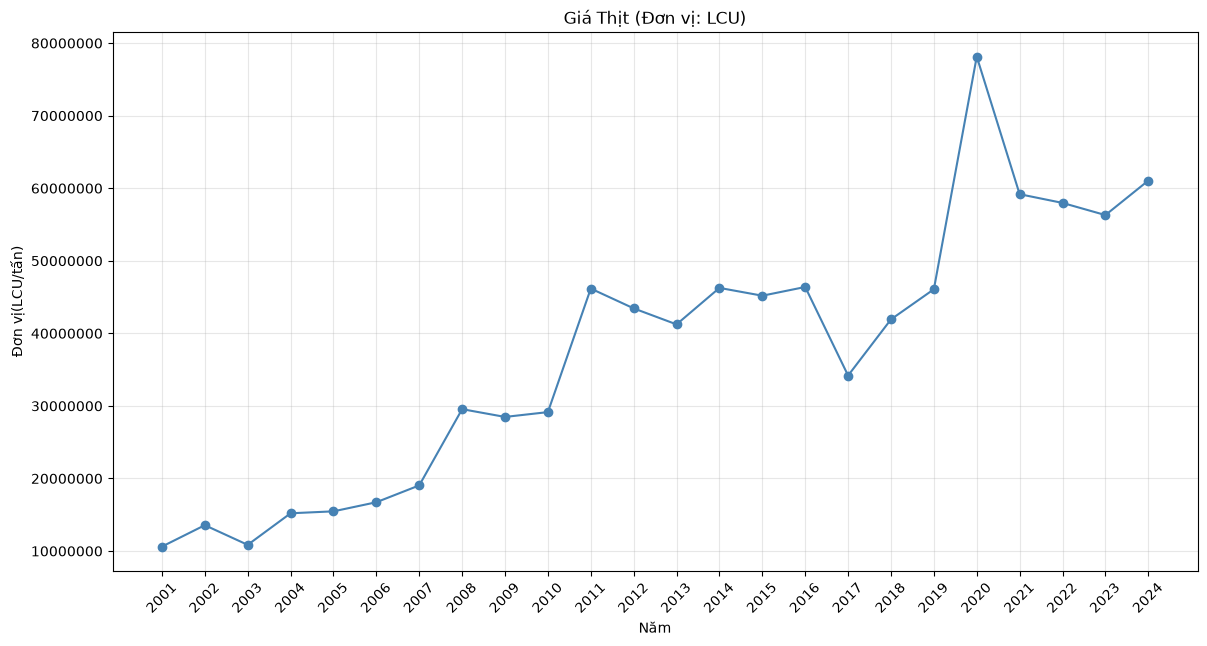

In [91]:
fig, ax = plt.subplots(figsize=(14,7))
ax.plot(df_Meat["Year"], df_Meat["Annual value"],marker= "o", color="steelblue")

ax.yaxis.set_major_locator(MultipleLocator(10_000_000))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0f}".replace(",", ".")))

ax.set_xticks(df_Meat["Year"])
ax.tick_params(axis="x", rotation=45)

ax.set_title("Giá Thịt (Đơn vị: LCU)")
ax.set_xlabel("Năm")
ax.set_ylabel("Đơn vị(LCU/tấn)")
ax.grid(True, alpha=0.3)
plt.show()

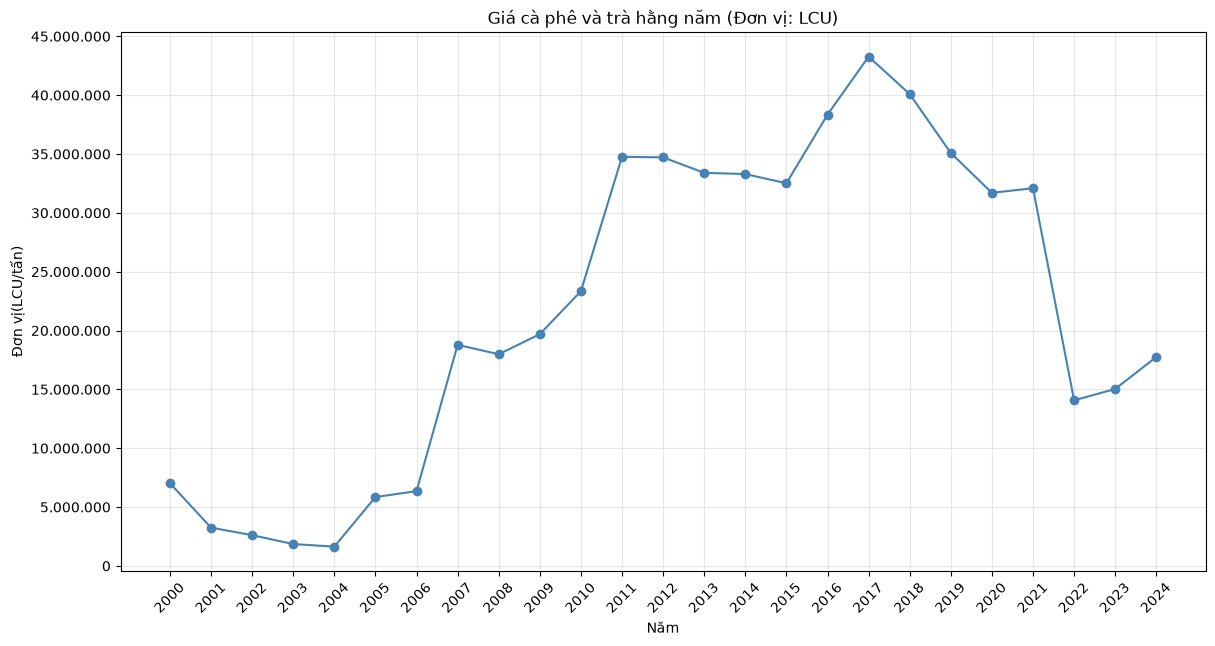

In [92]:
fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(df_coffee["Year"], df_coffee["Annual value"], marker="o", color="steelblue")

# Mốc mỗi 5 triệu, nhãn đầy đủ có dấu chấm
ax.yaxis.set_major_locator(MultipleLocator(5_000_000))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))

# Mốc năm mỗi 1 năm, xoay nhãn cho khỏi chồng
ax.set_xticks(df_coffee["Year"])
ax.tick_params(axis="x", rotation=45)

ax.set_title("Giá cà phê và trà hằng năm (Đơn vị: LCU)")
ax.set_xlabel("Năm")
ax.set_ylabel("Đơn vị(LCU/tấn)")
ax.grid(True, alpha=0.3)
plt.show()